In [ ]:
import json
from collections import Counter
from datetime import datetime
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

MAX_ELEMENTS = 3
MIN_ELEMENTS = 1

HERE = Path.cwd()
candidates = [HERE  / "data", 
              HERE,
              HERE / "notebook" / "data" / "data",
              HERE / "notebook" / "data"]
DATA_DIR = next((p for p in candidates if (p / "Stability.csv").exists()), None)
assert DATA_DIR is not None, "Stability.csv is not found. Run Stability.csv first"

IN_PATH = DATA_DIR / "Stability.csv"
OUT_PATH = DATA_DIR / "Composition.csv"
FIG_DIR = DATA_DIR.parent / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Input :", IN_PATH)
print("Output :", OUT_PATH)

Input : c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Stability.csv
Output : c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Composition.csv


In [ ]:
df = pd.read_csv(IN_PATH)
print("Stability.csv shape:", df.shape)

if "nelements" in df.columns:
    n_el = df["nelements"]
elif "elements" in df.columns:
    n_el = df["elements"].astype(str).str.split(r"[-_]").str.len()
else:
    raise AssertionError("Neither nelements nor elements is in the file.")
df["n_elements"] = n_el.astype("Int64")

if "elements" in df.columns:
    from_names = df["elements"].astype(str).str.split(r"[-_]").str.len()
    print("Rows where nelements disagrees with the element column:", int ((from_names != df["n_elements"]).sum()))

print()
print("Compounds by numbers of different elements:")
print(df["n_elements"].value_counts().sort_index())


Stability.csv shape: (38466, 17)
Rows where nelements disagrees with the element column: 0

Co;pounds by numbers of different elements:
n_elements
2     2333
3    15051
4    14332
5     5214
6     1483
7       45
8        8
Name: count, dtype: Int64


In [32]:
keep = df["n_elements"].between(MIN_ELEMENTS, MAX_ELEMENTS)
comp_df = df[keep].copy().reset_index(drop=True)

print("Screeen funnel")
print(f" Stability.csv                          : {len(df):,}")
print(f"    {MIN_ELEMENTS} to {MAX_ELEMENTS} different elements)                : {len(comp_df):,}")
print(f"    removed (more than {MAX_ELEMENTS} different elememts)       : {len(df) - len(comp_df):,}")
print()
print("kept, by number of different elements:")
print(comp_df["n_elements"].value_counts().sort_index())
comp_df.head()


Screeen funnel
 Stability.csv                          : 38,466
    1 to 3 different elements)                : 17,384
    removed (more than 3 different elememts)       : 21,082

kept, by number of different elements:
n_elements
2     2333
3    15051
Name: count, dtype: Int64


,formula,elements,nelements,nsites,volume,density,crystal_system,space_group,formation_energy_per_atom,energy_above_hull,is_stable,band_gap,cbm,vbm,is_gap_direct,theoretical,stability_class,n_elements
0,Ac2O3,Ac_O,2,5,91.511224,9.109130,Trigonal,P-3m1,-3.737668,0.0,True,3.5219,8.1120,4.5901,False,False,stable,2
1,Ac2S3,Ac_S,2,40,1118.407852,6.535149,Tetragonal,I-42d,-2.493064,0.0,True,2.2729,7.0869,4.8140,False,True,stable,2
2,AcAlO3,Ac_Al_O,3,5,57.451413,8.728230,Cubic,Pm-3m,-3.690019,0.0,True,4.1024,10.9060,6.8036,True,True,stable,3
3,AcBr3,Ac_Br,2,8,272.928947,5.679086,Hexagonal,P6_3/m,-2.494519,0.0,True,4.1034,5.1408,1.0374,False,False,stable,2
4,AcBrO,Ac_Br_O,3,6,140.139410,7.652290,Tetragonal,P4/nmm,-3.218186,0.0,True,4.2407,7.4413,3.2006,True,False,stable,3


Saved: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Composition.csv
{
  "saved_at": "2026-10-28T10:27:56",
  "input_file": "Stability.csv",
  "output_file": "Composition.csv",
  "min_elements": 1,
  "max_elements": 3,
  "rows_in": 38466,
  "rows_kept": 17384,
  "rows_removed": 21082,
  "rows_kept_by_n_elements": {
    "2": 2333,
    "3": 15051
  }
}


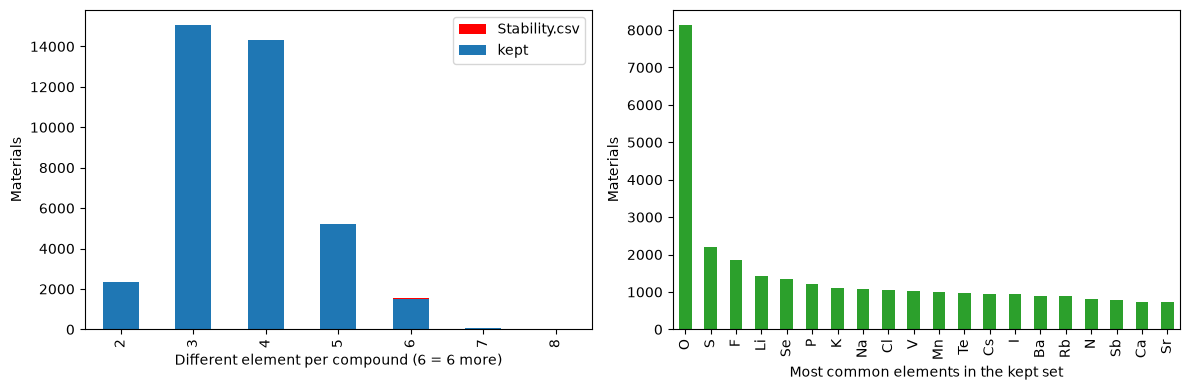

In [39]:
comp_df.to_csv(OUT_PATH, index=False)

summary = {
    "saved_at": datetime.now().isoformat(timespec="seconds"),
    "input_file": IN_PATH.name,
    "output_file": OUT_PATH.name,
    "min_elements": MIN_ELEMENTS,
    "max_elements": MAX_ELEMENTS,
    "rows_in": int(len(df)),
    "rows_kept": int(len(comp_df)),
    "rows_removed": int(len(df)) - int(len(comp_df)),
    "rows_kept_by_n_elements": {str(k): int(v) for k, v in comp_df["n_elements"].value_counts().sort_index().items()},

}
(DATA_DIR / f"{OUT_PATH.stem}_summary.json").write_text(json.dumps(summary, indent=2))
print("Saved:", OUT_PATH)
print(json.dumps(summary, indent=2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["n_elements"].clip(upper=6).value_counts().sort_index().plot.bar(ax=axes[0], color="red", label="Stability.csv")
df["n_elements"].value_counts().sort_index().plot.bar(ax=axes[0], color="tab:blue", label="kept")
axes[0].set_xlabel("Different element per compound (6 = 6 more)"); axes[0].set_ylabel("Materials"); axes[0].legend()
if "elements" in comp_df.columns:
    counts = Counter(el for s in comp_df["elements"].dropna().astype(str) for el in set(s.replace("_", "_").split("_")))
    top = pd.Series(counts).sort_values(ascending=False).head(20)
    top.plot.bar(ax=axes[1], color="tab:green")
    axes[1].set_xlabel("Most common elements in the kept set"); axes[1].set_ylabel("Materials")
plt.tight_layout()
plt.savefig(FIG_DIR / "composition_screening.png", dpi=200)
plt.show()